# Cluster persistence: do clusters stay the same from month to month?

If clusters change drastically every rebalance date, then any portfolio built on top of them will have massive turnover (the cluster representative changes constantly), and the structure I'm clustering on probably isn't real. If clusters are stable, the structure is real and the portfolio turnover is manageable.

The measure I use: for every pair of consecutive rebal dates, compare the cluster labels using the Hungarian algorithm to find the best label-permutation match. The persistence score is the fraction of tickers whose remapped current-date label equals their previous-date label. ARI is reported alongside as a permutation-invariant cross-check.

One thing this metric will surface that ARI alone hides: single and average linkage will look very "persistent" (close to 1) because they chain into one giant cluster that doesn't move. That's not real stability, that's pathological behavior. The summary table will show this clearly.


## 1. Setup and load the cluster artifacts

Six artifacts to compare: Q0_direct, Q0_pipeline, Q1 x {K11, Kmp}, Q2 x {K11, Kmp}. Q0_direct and Q0_pipeline only have kmeans and ward (avg / single were dropped after the chaining diagnostic in the clustering notebook). The four Q1 / Q2 artifacts have all four methods.


In [1]:
import numpy as np
import pandas as pd
import arcticdb as adb
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

ARCTIC_URI = "lmdb://./database/arctic"
ac = adb.Arctic(ARCTIC_URI)
clusters_lib = ac["clusters_lib"]
OUTPUTS = Path("outputs"); OUTPUTS.mkdir(exist_ok=True)

ARTIFACTS = {
    "Q0_direct":   ("q0direct_labels_K11", "K11"),
    "Q0_pipeline": ("q0_labels_K11",       "K11"),
    "Q1_K11":      ("q1_labels_K11",       "K11"),
    "Q1_Kmp":      ("q1_labels_Kmp",       "Kmp"),
    "Q2_K11":      ("q2_labels_K11",       "K11"),
    "Q2_Kmp":      ("q2_labels_Kmp",       "Kmp"),
}

METHODS = ["kmeans", "ward", "average", "single"]
for label, (sym, K_scheme) in ARTIFACTS.items():
    df = clusters_lib.read(sym).data
    methods_here = [m for m in METHODS if m in df.columns]
    print(f"{label:<14} ({sym:<24}) "
          f"shape={df.shape}  rebal_dates={df.index.get_level_values(0).nunique()}  "
          f"methods={methods_here}")


Q0_direct      (q0direct_labels_K11     ) shape=(139252, 2)  rebal_dates=290  methods=['kmeans', 'ward']
Q0_pipeline    (q0_labels_K11           ) shape=(141854, 2)  rebal_dates=290  methods=['kmeans', 'ward']
Q1_K11         (q1_labels_K11           ) shape=(135321, 4)  rebal_dates=290  methods=['kmeans', 'ward', 'average', 'single']
Q1_Kmp         (q1_labels_Kmp           ) shape=(135321, 4)  rebal_dates=290  methods=['kmeans', 'ward', 'average', 'single']
Q2_K11         (q2_labels_K11           ) shape=(128131, 4)  rebal_dates=290  methods=['kmeans', 'ward', 'average', 'single']
Q2_Kmp         (q2_labels_Kmp           ) shape=(128131, 4)  rebal_dates=290  methods=['kmeans', 'ward', 'average', 'single']


## 2. The persistence metric

Given two label arrays `prev` and `curr` of equal length (one per ticker, restricted to tickers present in both rebal dates), find the optimal mapping from current-date labels to previous-date labels using the Hungarian algorithm. The score is the fraction of tickers whose remapped label matches.

I also return ARI for cross-checking. Sanity-check on two random consecutive Q2 dates below.


In [2]:
def hungarian_persistence(prev, curr):
    """prev, curr: 1-D int arrays of equal length.
    Returns (persistence_fraction, ari, n)."""
    K = max(int(prev.max()), int(curr.max())) + 1
    cost = np.zeros((K, K), dtype=int)
    for i in range(K):
        mask_i = (prev == i)
        if not mask_i.any():
            continue
        for j in range(K):
            cost[i, j] = -((mask_i) & (curr == j)).sum()
    row_ind, col_ind = linear_sum_assignment(cost)
    remap = {col_ind[i]: row_ind[i] for i in range(len(row_ind))}
    curr_remapped = np.array([remap.get(int(x), -1) for x in curr])
    persistence = float((prev == curr_remapped).mean())
    ari = adjusted_rand_score(prev, curr)
    return persistence, ari, len(prev)


# Sanity check on two consecutive Q2 K11 kmeans rebal dates
df_q2 = clusters_lib.read("q2_labels_K11").data
dates = sorted(df_q2.index.get_level_values(0).unique())
prev, curr = dates[100], dates[101]
prev_s = df_q2.xs(prev, level=0)["kmeans"]
curr_s = df_q2.xs(curr, level=0)["kmeans"]
common = prev_s.index.intersection(curr_s.index)
p, a, n = hungarian_persistence(prev_s.loc[common].values, curr_s.loc[common].values)
print(f"Q2 K11 kmeans: {prev.date()} to {curr.date()}  n={n}  "
      f"persistence={p:.3f}  ARI={a:.3f}")


Q2 K11 kmeans: 2010-04-30 to 2010-06-01  n=406  persistence=0.796  ARI=0.610


## 3. Evaluate every (artifact, method, consecutive-date-pair)

For each of the six artifacts, walk through every consecutive pair of rebal dates and every method that's present, compute the persistence + ARI, and collect into one long-form DataFrame. Drop any pair with fewer than 50 common tickers.


In [3]:
def evaluate_artifact(panel_label, df, K_scheme):
    rows = []
    available = [m for m in METHODS if m in df.columns]
    if not available:
        return rows
    method_dates = {m: {d: g[m].droplevel(0) for d, g in df.groupby(level=0)}
                    for m in available}
    rebal_dates = sorted(method_dates[available[0]].keys())
    for prev_d, curr_d in zip(rebal_dates[:-1], rebal_dates[1:]):
        for m in available:
            prev_s = method_dates[m][prev_d]
            curr_s = method_dates[m][curr_d]
            common = prev_s.index.intersection(curr_s.index)
            if len(common) < 50:
                continue
            p, a, n = hungarian_persistence(
                prev_s.loc[common].values, curr_s.loc[common].values)
            rows.append({
                "panel": panel_label, "K_scheme": K_scheme, "method": m,
                "prev_date": prev_d, "curr_date": curr_d,
                "n_common": n, "persistence": p, "ari_prev_curr": a,
            })
    return rows


all_rows = []
for label, (sym, K_scheme) in ARTIFACTS.items():
    df = clusters_lib.read(sym).data
    print(f"  evaluating {label} ...")
    all_rows.extend(evaluate_artifact(label, df, K_scheme))

per_pair = pd.DataFrame(all_rows)
per_pair.to_csv(OUTPUTS / "cluster_persistence.csv", index=False)
print(f"\n{len(per_pair)} rows written to {OUTPUTS / 'cluster_persistence.csv'}")
per_pair.head()


  evaluating Q0_direct ...


  evaluating Q0_pipeline ...


  evaluating Q1_K11 ...


  evaluating Q1_Kmp ...


  evaluating Q2_K11 ...


  evaluating Q2_Kmp ...



5780 rows written to outputs/cluster_persistence.csv


,panel,K_scheme,method,prev_date,curr_date,n_common,persistence,ari_prev_curr
0,Q0_direct,K11,kmeans,2001-12-31,2002-02-01,467,0.783726,0.672085
1,Q0_direct,K11,ward,2001-12-31,2002-02-01,467,0.725910,0.493726
2,Q0_direct,K11,kmeans,2002-02-01,2002-03-01,467,0.817987,0.732665
3,Q0_direct,K11,ward,2002-02-01,2002-03-01,467,0.888651,0.706490
4,Q0_direct,K11,kmeans,2002-03-01,2002-04-01,469,0.742004,0.641664


## 4. Summary table

Mean and std of persistence across all 289 transition pairs, grouped by (panel, K_scheme, method). The mean ARI is included for cross-checking.


In [4]:
summary = (per_pair
            .groupby(["panel", "K_scheme", "method"])
            .agg(persistence_mean=("persistence", "mean"),
                 persistence_std=("persistence", "std"),
                 ari_mean=("ari_prev_curr", "mean"),
                 n_pairs=("persistence", "size"))
            .round(4)
            .reset_index())
summary.to_csv(OUTPUTS / "cluster_persistence_summary.csv", index=False)
print(summary.to_string(index=False))


      panel K_scheme  method  persistence_mean  persistence_std  ari_mean  n_pairs
  Q0_direct      K11  kmeans            0.6839           0.0896    0.5080      289
  Q0_direct      K11    ward            0.7627           0.0895    0.5687      289
Q0_pipeline      K11  kmeans            0.7601           0.0941    0.5682      289
Q0_pipeline      K11    ward            0.7212           0.0973    0.4708      289
     Q1_K11      K11 average            0.9854           0.0153    0.7880      289
     Q1_K11      K11  kmeans            0.7061           0.0961    0.4905      289
     Q1_K11      K11  single            0.9915           0.0059    0.8175      289
     Q1_K11      K11    ward            0.7460           0.1097    0.5075      289
     Q1_Kmp      Kmp average            0.9788           0.0144    0.7831      289
     Q1_Kmp      Kmp  kmeans            0.7038           0.0918    0.5077      289
     Q1_Kmp      Kmp  single            0.9886           0.0070    0.8275      289
    

## 5. Bar chart: mean persistence per (panel, method, K_scheme)

This plot makes the chaining pathology visible immediately. Single and average linkage sit at around 0.99 (the dotted line) because almost everything is in the one big cluster, which doesn't move. Kmeans and Ward sit in the 0.65 to 0.77 range, which is the *real* reorganization rate. The lower one of those is the actual turnover the portfolio will see.


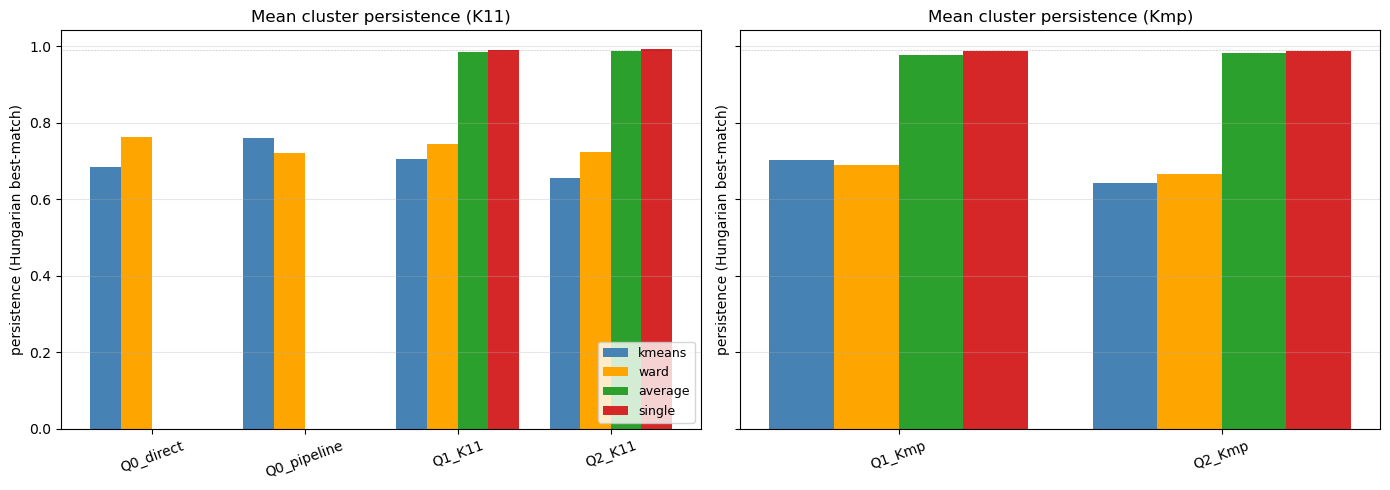

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, K_scheme in zip(axes, ["K11", "Kmp"]):
    sub = summary[summary["K_scheme"] == K_scheme]
    panels_order = sorted(sub["panel"].unique())
    methods_order = ["kmeans", "ward", "average", "single"]
    x = np.arange(len(panels_order))
    width = 0.2
    colors = {"kmeans": "steelblue", "ward": "orange",
              "average": "tab:green", "single": "tab:red"}
    for i, m in enumerate(methods_order):
        rows = sub[sub["method"] == m]
        vals = [rows[rows["panel"] == p]["persistence_mean"].values[0]
                if (rows["panel"] == p).any() else float("nan")
                for p in panels_order]
        ax.bar(x + i * width, vals, width, label=m, color=colors[m])
    ax.set_xticks(x + 1.5 * width)
    ax.set_xticklabels(panels_order, rotation=20)
    ax.set_title(f"Mean cluster persistence ({K_scheme})")
    ax.set_ylabel("persistence (Hungarian best-match)")
    ax.axhline(0.99, color="black", lw=0.4, ls=":", alpha=0.5)
    ax.grid(alpha=0.3, axis="y")
axes[0].legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUTS / "cluster_persistence_bars.png", dpi=130)
plt.show()


## 6. Persistence over time

Same idea, but as a time series for kmeans only (the diagnostic method). Crisis markers for orientation. Expect dips during stress regimes: when correlations spike, clusters reshuffle faster than usual.


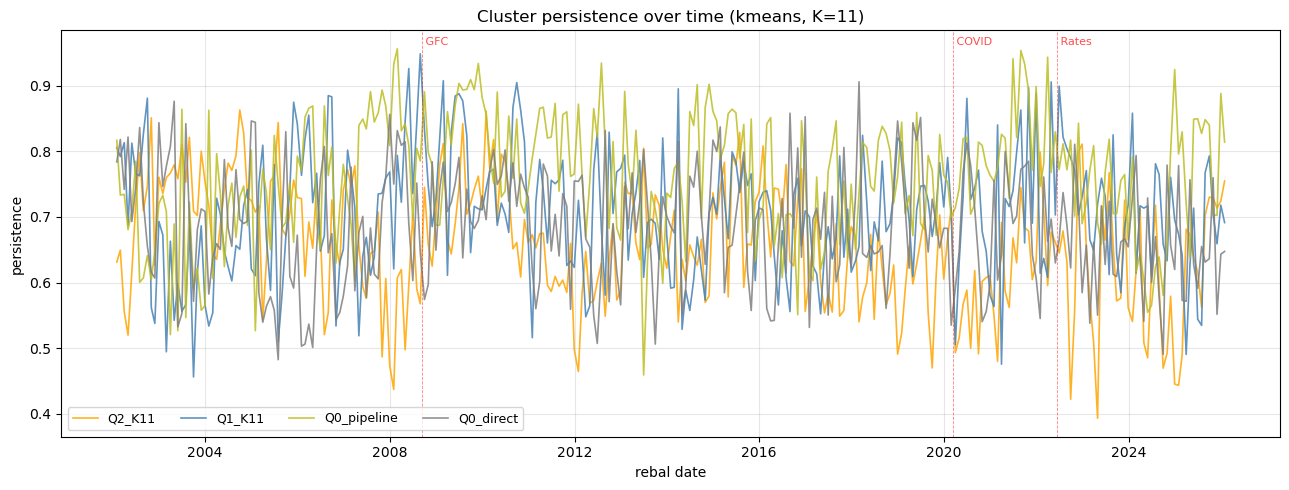

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
for panel_full, color in [("Q2_K11", "orange"), ("Q1_K11", "steelblue"),
                           ("Q0_pipeline", "tab:olive"), ("Q0_direct", "tab:gray")]:
    sub = per_pair[(per_pair["panel"] == panel_full)
                    & (per_pair["method"] == "kmeans")].sort_values("curr_date")
    ax.plot(sub["curr_date"], sub["persistence"], color=color, lw=1.2,
            label=panel_full, alpha=0.85)

for x, lab in [("2008-09-15", "GFC"), ("2020-03-15", "COVID"),
                ("2022-06-15", "Rates")]:
    ax.axvline(pd.Timestamp(x), color="red", lw=0.6, ls="--", alpha=0.5)
    ax.text(pd.Timestamp(x), ax.get_ylim()[1] * 0.99, " " + lab,
            color="red", fontsize=8, alpha=0.7, va="top")
ax.set_title("Cluster persistence over time (kmeans, K=11)")
ax.set_ylabel("persistence")
ax.set_xlabel("rebal date")
ax.legend(loc="lower left", ncol=4, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUTS / "cluster_persistence_timeseries.png", dpi=130)
plt.show()


## What this tells me

- Single and average linkage cluster about 99% "persistent" by construction, because they chain into one giant cluster plus K-1 singletons. The giant doesn't move, so persistence looks great. This shows up right next to the high ARI numbers for the same methods in the eval notebook and tells me both metrics are misleadingly stable on these methods. Drop them from any portfolio work.

- Kmeans and Ward at 65-77% persistence is the real number. About a quarter to a third of (ticker, cluster) assignments change every month. Q2 kmeans is the least stable at around 66%, which matches the ~60% portfolio turnover I measured in the cluster-portfolios notebook.

- Time-series dips during stress periods (2008, 2020, 2022) are visible. During regime stress, factor structure reshuffles faster, so clusters reshuffle too. This is consistent with the MP-survivor-count time series from the preprocessing notebook: when the number of real factors compresses, the cluster boundaries shift too.

For the portfolio work downstream, the takeaway is: kmeans and Ward on Q1 are the most stable cluster-portfolio candidates at around 74% persistence, but no clustering method here is stable enough to give a low-turnover portfolio without re-thinking the selection rule.
